# Trajectory Prediction on Real Highway Data

**Module 01 · Perception and Prediction** · Notebook 9 of 9

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/01_Perception/09_trajectory_prediction.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [07 Multi-object tracking](07_multi_object_tracking.ipynb); basic probability; helpful: [06-05 Conformal prediction](../06_AI_Safety_ISO_PAS_8800/05_conformal_prediction.ipynb) | ISO 21448:2022 (performance insufficiencies); ISO/PAS 8800:2024 (AI components) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Prepare real NGSIM vehicle trajectories for prediction: units, time base, re-used vehicle IDs, measurement noise and smoothing without information leakage.
2. Implement physics-based baselines (constant velocity, constant acceleration, constant turn rate and velocity) and explain where each one fails.
3. Train a small multimodal predictor (a mixture density network) on CPU and compare it with a manoeuvre-based baseline.
4. Compute ADE, FDE, minADE$_K$, minFDE$_K$, miss rate and negative log-likelihood, and explain what each metric rewards and hides.
5. Check whether predicted uncertainty is **calibrated** (coverage of prediction regions) and repair marginal coverage with split conformal prediction.
6. Analyse failures on real lane changes and stop-and-go waves, and translate prediction error into planning risk (RSS safety distance, cut-in recognition).

## 1. Why prediction is a safety function

A tracker ([Notebook 07](07_multi_object_tracking.ipynb)) tells the planner where objects are and how fast they move *now*. The planner, however, decides on a manoeuvre that will take several seconds, so it needs to know where the other road users will be over that horizon. **Motion prediction** fills this gap, and its errors propagate directly into the plan:

- predicting a lead vehicle **further ahead** than it will be (e.g. missing that it brakes into a queue) makes the planned gap look larger than it is;
- missing a **lane change** delays the reaction to a cut-in;
- predicting **too narrow** an uncertainty region lets the planner commit to a manoeuvre that is only safe for the most likely future.

Lefèvre, Vasquez and Laugier (2014) group prediction methods into **physics-based** (kinematic models), **manoeuvre-based** (recognise the intended manoeuvre, then predict it) and **interaction-aware** models (account for the influence of other road users). We implement members of the first two groups and a small learned model, on real highway data, using the task popularised on NGSIM by Deo and Trivedi (2018): **3 s of history, 5 s of prediction**.

None of these models are state of the art; they are chosen because they are small enough to read, run on a CPU in seconds and show the safety-relevant failure modes clearly. Section 10 points to current methods and benchmarks.

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D
from avsafety import sotif, uq

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.stats import chi2
import torch

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
OI = {"orange": "#E69F00", "skyblue": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "black": "#000000"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})
T0 = time.time()

## 2. The data: NGSIM US-101

The Next Generation Simulation (NGSIM) programme of the US Federal Highway Administration recorded vehicle trajectories from video to support traffic-model development (Alexiadis et al., 2004). The **US-101** data set (FHWA, 2007) covers about 640 m of the southbound Hollywood Freeway in Los Angeles with five mainline lanes and an auxiliary lane between an on-ramp and an off-ramp. Eight synchronised cameras on a 36-storey building recorded traffic on 15 June 2005 between 7:50 and 8:35 a.m., during the build-up of congestion. Trajectories were extracted from the video at 10 Hz.

We load a **three-minute window (8:00:00–8:03:00 local time)** through the US DOT open-data API. That is about 245,000 rows and 49 MB of JSON on first download (cached afterwards).

> **Data and licence.** NGSIM is US government data in the public domain; cite the programme and the data set (references below). The printed attribution comes from `avsafety.data`.

In [2]:
WINDOW_START_MS = 1118847600000          # 2005-06-15 15:00:00 UTC = 08:00:00 PDT
WINDOW_S = 180
COLUMNS = "vehicle_id,frame_id,global_time,local_x,local_y,v_vel,v_acc,lane_id,v_class,v_length,v_width"
t_load = time.time()
try:
    raw = D.ngsim("us-101", where=f"global_time >= {WINDOW_START_MS} AND global_time < {WINDOW_START_MS + WINDOW_S * 1000}",
                  limit=300_000, select=COLUMNS)
except D.DataUnavailable as exc:
    raise SystemExit(f"NGSIM could not be downloaded ({exc}). This notebook needs the real data; "
                     "check the network connection and re-run.")
print(f"{len(raw):,} rows, {raw['vehicle_id'].nunique()} vehicle IDs, loaded in {time.time() - t_load:.1f} s")
print(D.attribution("NGSIM"))
raw.head(3)

245,495 rows, 577 vehicle IDs, loaded in 2.9 s
Data: US DOT Next Generation Simulation (NGSIM) vehicle trajectories, public domain, https://data.transportation.gov/d/8ect-6jqj


,vehicle_id,frame_id,global_time,local_x,local_y,v_vel,v_acc,lane_id,v_class,v_length,v_width
0,1964,6211,1118847600000,10.019,2068.172,39.28,3.52,1,2,12.0,5.5
1,1964,6212,1118847600100,10.090,2072.123,39.61,2.90,1,2,12.0,5.5
2,1964,6213,1118847600200,10.127,2076.105,39.84,1.91,1,2,12.0,5.5


### 2.1 Units, time base and vehicle identity

Three properties of the raw data cause silent errors if they are ignored:

| Field | Raw unit | Conversion |
|---|---|---|
| `local_y` (along the road), `local_x` (across the road, from the left edge) | feet | × 0.3048 → m |
| `v_vel`, `v_acc` | ft/s, ft/s² | × 0.3048 → m/s, m/s² |
| `global_time` | milliseconds since 1 January 1970 (UTC) | ÷ 1000 → s |

`vehicle_id` is unique only within one 15-minute period; the same number re-appears in later periods for a different vehicle. We therefore start a new **segment** wherever the time stamps of an ID jump, and re-sample every segment onto an exact 0.1 s grid (the data are nominally 10 Hz; re-sampling makes that an enforced property rather than an assumption, and bridges isolated missing samples by linear interpolation).

In [3]:
FT = 0.3048
DT = 0.1
LANE_W = 12 * FT                         # US-101 lane width, 12 ft


def to_si(raw):
    df = raw.sort_values(["vehicle_id", "global_time"]).reset_index(drop=True)
    out = pd.DataFrame({"vid": df["vehicle_id"].astype(int),
                        "t": (df["global_time"] - WINDOW_START_MS) / 1000.0,      # ms -> s
                        "x": df["local_y"] * FT,                                   # along the road [m]
                        "y": df["local_x"] * FT,                                   # across the road [m]
                        "v_rep": df["v_vel"] * FT,                                 # reported speed [m/s]
                        "lane": df["lane_id"].astype(int), "cls": df["v_class"].astype(int)})
    new_seg = (out["vid"].diff() != 0) | (out["t"].diff().abs() > 1.5 * DT)       # re-used IDs, gaps
    out["seg"] = np.cumsum(new_seg)
    return out


def resample(g, dt=DT):
    tt = np.round(np.arange(g["t"].iloc[0], g["t"].iloc[-1] + 1e-9, dt), 3)
    r = pd.DataFrame({"t": tt})
    for c in ["x", "y", "v_rep"]:
        r[c] = np.interp(tt, g["t"].values, g[c].values)
    r["lane"] = g["lane"].values[np.searchsorted(g["t"].values, tt, side="right") - 1]   # last known lane
    r["seg"], r["vid"], r["cls"] = g["seg"].iloc[0], g["vid"].iloc[0], g["cls"].iloc[0]
    return r


ng = to_si(raw)
steps = ng.groupby("seg")["t"].diff().dropna()
print(f"{ng['seg'].nunique()} segments; time steps: {100 * np.mean(np.isclose(steps, DT)):.2f} % exactly 0.1 s")
print(f"Lanes present: {sorted(int(l) for l in ng['lane'].unique())} (1-5 mainline, 6 auxiliary, 7 on-ramp, 8 off-ramp)")
print(f"Vehicle classes: {ng.groupby('cls')['seg'].nunique().rename({1: 'motorcycle', 2: 'car', 3: 'truck'}).to_dict()}")

577 segments; time steps: 100.00 % exactly 0.1 s
Lanes present: [1, 2, 3, 4, 5, 6, 7, 8] (1-5 mainline, 6 auxiliary, 7 on-ramp, 8 off-ramp)
Vehicle classes: {'motorcycle': 5, 'car': 563, 'truck': 9}


### 2.2 Measurement noise and smoothing

Video-extracted positions carry pixel-level noise that differentiation amplifies: speeds and accelerations computed directly from NGSIM positions contain physically implausible values. This is documented in detail by Thiemann, Treiber and Kesting (2008), Punzo, Borzacchiello and Ciuffo (2011) and Coifman and Li (2017), the last of which also reports systematic errors in the data set's vehicle lengths and positions. Two consequences matter here:

1. **The reference trajectory** that we score predictions against should be smoothed, otherwise every metric contains a noise floor that no predictor can remove. We use a centred Savitzky–Golay filter (cubic, 2.1 s window), which is allowed for ground truth because ground truth may look into the future.
2. **The predictor's inputs** must be smoothed **causally**, using only the 3 s history. Smoothing the whole trajectory first and then cutting history windows out of it leaks future information into the inputs and makes every model look better than it would be in a vehicle. This is one of the most common errors in published prediction pipelines.

Longitudinal acceleration from raw positions     :  5.52 % of samples beyond +-4 m/s^2, 99.9th percentile of |a| = 14.2 m/s^2
Longitudinal acceleration from smoothed reference:  0.58 % of samples beyond +-4 m/s^2, 99.9th percentile of |a| = 7.7 m/s^2


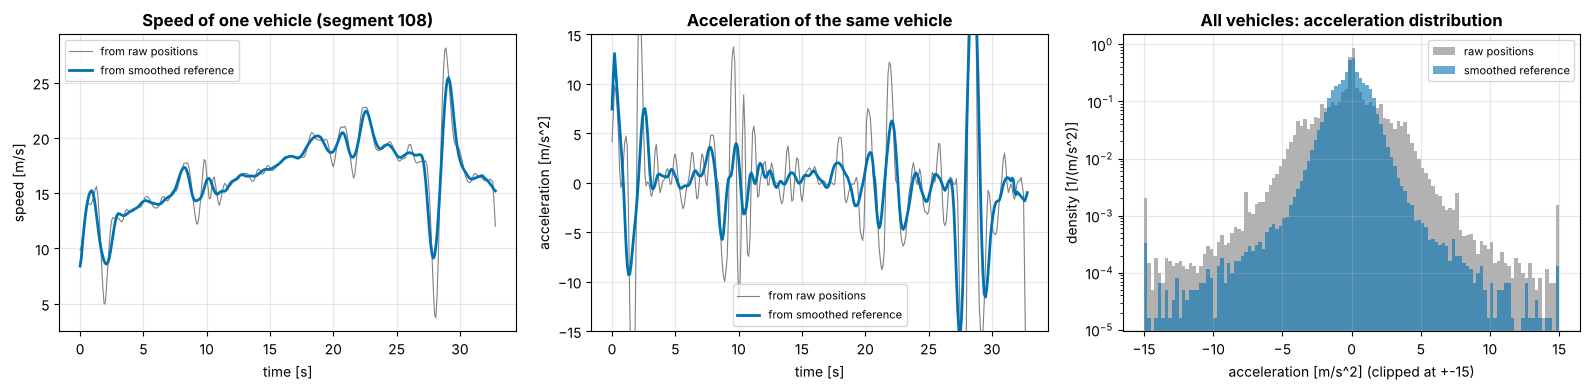

In [4]:
SMOOTH_WIN = 21                          # 2.1 s centred Savitzky-Golay window for the reference trajectory
segs = []
for s, g in ng.groupby("seg"):
    if len(g) < SMOOTH_WIN:
        continue
    r = resample(g)
    r["xs"] = savgol_filter(r["x"].values, SMOOTH_WIN, 3)
    r["ys"] = savgol_filter(r["y"].values, SMOOTH_WIN, 3)
    segs.append(r)
traj = pd.concat(segs, ignore_index=True)


def second_derivative(v):
    return np.gradient(np.gradient(v, DT), DT)


a_raw = np.concatenate([second_derivative(g["x"].values) for _, g in traj.groupby("seg")])
a_ref = np.concatenate([second_derivative(g["xs"].values) for _, g in traj.groupby("seg")])
for name, a in [("raw positions", a_raw), ("smoothed reference", a_ref)]:
    print(f"Longitudinal acceleration from {name:18s}: {100 * np.mean(np.abs(a) > 4):5.2f} % of samples beyond "
          f"+-4 m/s^2, 99.9th percentile of |a| = {np.percentile(np.abs(a), 99.9):.1f} m/s^2")

# one vehicle as an example: the segment with the largest speed range
ex_seg = traj.groupby("seg")["v_rep"].agg(lambda v: v.max() - v.min()).idxmax()
ex = traj[traj["seg"] == ex_seg]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ex["t"], np.gradient(ex["x"], DT), color="grey", lw=0.8, label="from raw positions")
axes[0].plot(ex["t"], np.gradient(ex["xs"], DT), color=OI["blue"], lw=2, label="from smoothed reference")
axes[0].set(title=f"Speed of one vehicle (segment {ex_seg})", xlabel="time [s]", ylabel="speed [m/s]")
axes[1].plot(ex["t"], second_derivative(ex["x"].values), color="grey", lw=0.8, label="from raw positions")
axes[1].plot(ex["t"], second_derivative(ex["xs"].values), color=OI["blue"], lw=2, label="from smoothed reference")
axes[1].set(title="Acceleration of the same vehicle", xlabel="time [s]", ylabel="acceleration [m/s^2]", ylim=(-15, 15))
bins = np.linspace(-15, 15, 121)
axes[2].hist(np.clip(a_raw, -15, 15), bins=bins, color="grey", alpha=0.6, density=True, label="raw positions")
axes[2].hist(np.clip(a_ref, -15, 15), bins=bins, color=OI["blue"], alpha=0.6, density=True, label="smoothed reference")
axes[2].set(title="All vehicles: acceleration distribution", xlabel="acceleration [m/s^2] (clipped at +-15)",
            ylabel="density [1/(m/s^2)]", yscale="log")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 2.3 What traffic looks like in this window

A **time–space diagram** plots each vehicle's position along the road against time. In congested traffic, **stop-and-go waves** appear as bands of low speed that travel *upstream* (against the direction of travel) while vehicles drive through them. For a predictor these waves are the hardest longitudinal case: a vehicle that is cruising now will brake within the next seconds because of a disturbance it, and the predictor, may not yet be able to see.

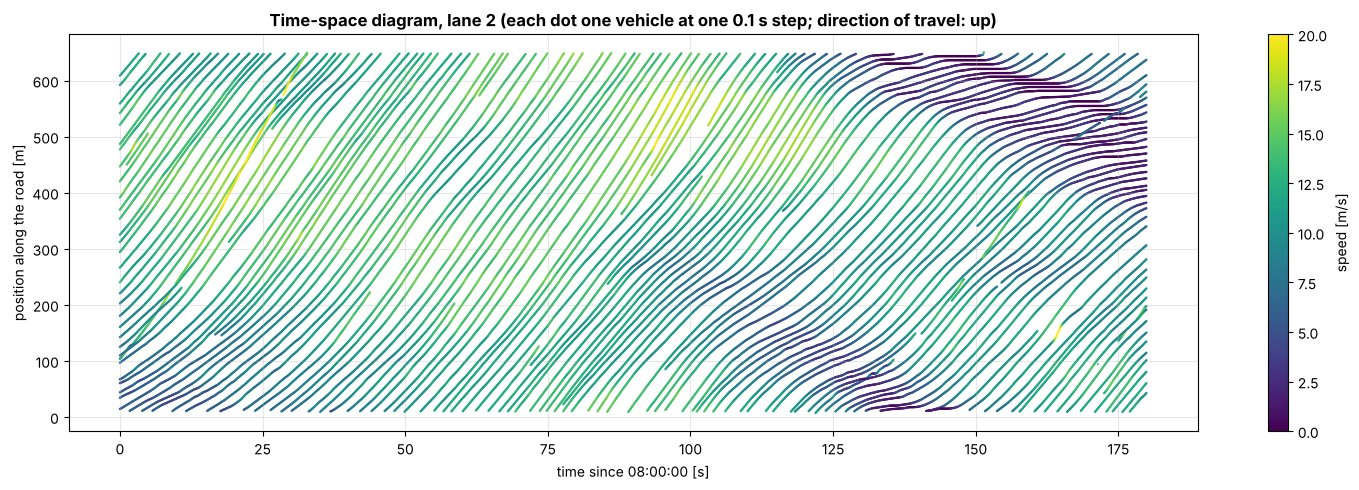

Median speed 11.5 m/s (42 km/h); 5.7 % of samples below 3 m/s; 222 lane changes by 112 of 564 vehicles in 3 minutes.


In [5]:
LANE_TS = 2
speed_ref = np.concatenate([np.gradient(g["xs"].values, DT) for _, g in traj.groupby("seg")])
traj["v"] = speed_ref
fig, ax = plt.subplots(figsize=(15, 5))
sc = ax.scatter(traj.loc[traj["lane"] == LANE_TS, "t"], traj.loc[traj["lane"] == LANE_TS, "x"], s=0.4,
                c=traj.loc[traj["lane"] == LANE_TS, "v"].clip(0, 20), cmap="viridis", rasterized=True)
plt.colorbar(sc, ax=ax, label="speed [m/s]")
ax.set(title=f"Time-space diagram, lane {LANE_TS} (each dot one vehicle at one 0.1 s step; direction of travel: up)",
       xlabel="time since 08:00:00 [s]", ylabel="position along the road [m]")
plt.tight_layout(); plt.show()

lane_changes = traj.groupby("seg")["lane"].apply(lambda s: int((s.diff().fillna(0) != 0).sum()))
print(f"Median speed {np.median(traj['v']):.1f} m/s ({3.6 * np.median(traj['v']):.0f} km/h); "
      f"{100 * np.mean(traj['v'] < 3):.1f} % of samples below 3 m/s; "
      f"{lane_changes.sum()} lane changes by {(lane_changes > 0).sum()} of {len(lane_changes)} vehicles in 3 minutes.")

## 3. The prediction task

Each **sample** is one vehicle at one time $t_0$:

- **input:** its own positions over the last 3 s (31 samples at 10 Hz), smoothed inside that window only, and expressed relative to its current position;
- **target:** its reference positions at $t_0 + 0.5, 1.0, \dots, 5.0$ s (10 points), relative to the same origin.

We take one sample per vehicle per second (consecutive samples overlap, so they are not independent), and split **by vehicle** into training (60 %), calibration (20 %) and test (20 %) sets. A split by sample would put almost identical neighbouring samples of the same vehicle into training and test.

To analyse failures we label each sample with a **regime**, using the reference trajectory:

| Regime | Rule |
|---|---|
| lane change | the lane ID changes within the 5 s horizon |
| braking into a wave | speed falls by more than 3 m/s below the current speed within the horizon |
| accelerating out | speed at the end of the horizon is more than 3 m/s above the current speed |
| steady | none of the above |

The interactions with surrounding vehicles that cause these regimes are not given to our models; this is deliberate, and Section 10 returns to it.

In [6]:
H_STEPS, F_STEPS, STRIDE = 30, 50, 10            # 3 s history, 5 s horizon, one sample per second
TAU_IDX = np.arange(5, F_STEPS + 1, 5)           # predicted points every 0.5 s
TAU = TAU_IDX * DT
HIST_WIN = 11                                    # 1.1 s Savitzky-Golay window, applied inside the history only
# Lateral motion is small compared with the lateral position noise, so the lateral velocity uses a longer,
# straight-line fit; an end-point derivative of a short quadratic fit would turn noise into apparent drift.
n_h = H_STEPS + 1
# Savitzky-Golay smoothing and differentiation of a fixed-length window are linear maps; build them once
EYE = np.eye(n_h)
M_SMOOTH = savgol_filter(EYE, HIST_WIN, 2, axis=0)
M_VEL = savgol_filter(EYE, HIST_WIN, 2, deriv=1, delta=DT, axis=0)          # longitudinal velocity
M_VEL_LAT = savgol_filter(EYE, 21, 1, deriv=1, delta=DT, axis=0)          # lateral: straight-line fit over 2.1 s
C_ACC = savgol_filter(EYE, 21, 2, deriv=2, delta=DT, axis=0)[-1]

blocks = []
for s, g in traj.groupby("seg"):
    if len(g) < n_h + F_STEPS:
        continue
    ks = np.arange(H_STEPS, len(g) - F_STEPS, STRIDE)
    win = ks[:, None] + np.arange(-H_STEPS, 1)[None]
    Xw, Yw = g["x"].values[win], g["y"].values[win]                 # raw history windows
    XS, YS, L = g["xs"].values, g["ys"].values, g["lane"].values     # reference trajectory (targets only)
    xs, ys = Xw @ M_SMOOTH.T, Yw @ M_SMOOTH.T
    vxs, vys = Xw @ M_VEL.T, Yw @ M_VEL_LAT.T
    psi = np.arctan2(vys, np.maximum(vxs, 1e-3))
    lane_f = L[ks[:, None] + np.arange(1, F_STEPS + 1)[None]]
    changed = lane_f != L[ks][:, None]
    first = np.where(changed.any(1), changed.argmax(1), -1)
    vref = np.gradient(XS, DT)[ks[:, None] + np.arange(0, F_STEPS + 1)[None]]
    fut_idx = ks[:, None] + TAU_IDX[None]
    blocks.append(dict(
        seg=np.full(len(ks), s), t=g["t"].values[ks], lane=L[ks], y0=ys[:, -1],
        vx=vxs[:, -1], vy=vys[:, -1], ax=Xw @ C_ACC, ay=Yw @ C_ACC,
        yaw_rate=np.where(np.hypot(vxs[:, -1], vys[:, -1]) > 1.0, psi[:, -1] - psi[:, -11], 0.0),   # over 1 s
        v_fut_min=vref.min(1), v_fut_end=vref[:, -1],
        t_lc=np.where(first >= 0, (first + 1) * DT, np.nan),
        lc_dir=np.where(first >= 0, np.sign(lane_f[np.arange(len(ks)), np.maximum(first, 0)] - L[ks]), 0),
        hist=np.stack([xs - xs[:, -1:], ys - ys[:, -1:]], -1),
        fut=np.stack([XS[fut_idx] - xs[:, -1:], YS[fut_idx] - ys[:, -1:]], -1)))
HIST = np.concatenate([b.pop("hist") for b in blocks])            # N x 31 x 2
FUT = np.concatenate([b.pop("fut") for b in blocks])              # N x 10 x 2
S = pd.DataFrame({k: np.concatenate([b[k] for b in blocks]) for k in blocks[0]})
S["v_now"] = np.hypot(S["vx"], S["vy"])
S["regime"] = np.select([S["t_lc"].notna(), S["v_fut_min"] < S["v_now"] - 3.0, S["v_fut_end"] > S["v_now"] + 3.0],
                        ["lane change", "braking into a wave", "accelerating out"], "steady")

segs_u = S["seg"].unique().copy()
rng.shuffle(segs_u)
split = {s: ("train" if i < 0.6 * len(segs_u) else "cal" if i < 0.8 * len(segs_u) else "test")
         for i, s in enumerate(segs_u)}
S["split"] = S["seg"].map(split)
tr, ca, te = [(S["split"] == k).values for k in ["train", "cal", "test"]]
print(f"{len(S):,} samples from {S['seg'].nunique()} vehicle segments")
print(S.groupby(["regime", "split"]).size().unstack()[["train", "cal", "test"]].to_string())

20,364 samples from 530 vehicle segments
split                train   cal  test
regime                                
accelerating out      1290   382   393
braking into a wave   1820   631   517
lane change            386   126   109
steady                8933  2873  2904


## 4. Physics-based baselines

All three extrapolate the current state, estimated from the smoothed history, with $\tau$ the prediction horizon:

- **Constant velocity (CV):** $\mathbf{p}(\tau) = \mathbf{v}\,\tau$.
- **Constant acceleration (CA):** $\mathbf{p}(\tau) = \mathbf{v}\,\tau + \tfrac12\mathbf{a}\,\tau^2$.
- **Constant turn rate and velocity (CTRV)** (see Schubert, Richter and Wanielik, 2008): speed $v$ and heading $\psi$ from the velocity, yaw rate $\omega$ from the heading change over the last second,
$$x(\tau) = \tfrac{v}{\omega}\big(\sin(\psi + \omega\tau) - \sin\psi\big),\qquad y(\tau) = \tfrac{v}{\omega}\big(\cos\psi - \cos(\psi + \omega\tau)\big),$$
with the CV limit for $\omega \to 0$. On a straight highway, the "turn" is lateral drift; we clip $|\omega| \le 0.3$ rad/s.

To compare them on likelihood and calibration, each needs a predictive distribution. We give each a Gaussian with a per-horizon, per-axis standard deviation equal to the spread of its residuals on the **training** set. This is the simplest honest error model: it is calibrated on average, by construction, but has the same width for every vehicle.

In [7]:
def pred_cv(S):
    return np.einsum("t,nd->ntd", TAU, S[["vx", "vy"]].values)


def pred_ca(S):
    return pred_cv(S) + 0.5 * np.einsum("t,nd->ntd", TAU**2, S[["ax", "ay"]].values)


def pred_ctrv(S):
    v = S["v_now"].values[:, None]; psi = np.arctan2(S["vy"], S["vx"]).values[:, None]
    om = np.clip(S["yaw_rate"].values, -0.3, 0.3)[:, None]
    om_safe = np.where(np.abs(om) < 1e-4, 1e-4, om)
    x = v / om_safe * (np.sin(psi + om_safe * TAU) - np.sin(psi))
    y = v / om_safe * (np.cos(psi) - np.cos(psi + om_safe * TAU))
    return np.where(np.abs(om)[..., None] < 1e-4, pred_cv(S), np.stack([x, y], -1))


def with_training_spread(pred):
    # Gaussian predictive distribution: per-horizon, per-axis SD of the training residuals
    sig = (FUT[tr] - pred[tr]).std(axis=0)
    return pred[:, None], np.broadcast_to(sig, pred.shape)[:, None].copy(), np.ones((len(pred), 1))


CV = pred_cv(S)
MODELS = {"CV": with_training_spread(CV), "CA": with_training_spread(pred_ca(S)),
          "CTRV": with_training_spread(pred_ctrv(S))}
# Every model is stored as (means N x K x 10 x 2, SDs N x K x 10 x 2, mode probabilities N x K)

## 5. Multimodal predictors

A single trajectory cannot represent "it may keep its lane or change left". Two ways to obtain several hypotheses:

**Manoeuvre-based mixture.** Keep the CV prediction and add two lane-change hypotheses: a smooth lateral shift of one lane width (3.66 m) completed within 4 s, to the left and to the right. Their probabilities are the lane-change frequencies in the training set; each hypothesis gets the CV spread. This encodes expert knowledge of the manoeuvre set but no evidence about *this* vehicle's intention.

**Mixture density network (MDN).** A small multilayer perceptron (two hidden layers of 128 units) maps the history features to $K$ trajectory hypotheses, each with a mean and a standard deviation per time step and axis, and a probability $\pi_k$ (Bishop, 1994). It is trained by minimising the negative log-likelihood of the observed future,
$$\mathcal{L} = -\log \sum_{k=1}^{K} \pi_k \prod_{t,d} \mathcal{N}\!\left(y_{t,d};\ \mu_{k,t,d},\ \sigma_{k,t,d}^2\right),$$
the same principle as in MultiPath (Chai et al., 2019), without anchors or a map. Two choices keep it small and stable: the network predicts a **residual** to the CV extrapolation, and we train $K=1$ and $K=3$ for comparison. Training takes some tens of seconds on one CPU thread; the network is too small for multi-threading to help.

In [8]:
def lc_profile(tau, T=4.0):
    s = np.clip(tau / T, 0, 1)
    return LANE_W * (3 * s**2 - 2 * s**3)            # smooth lateral shift of one lane width within T seconds


p_left, p_right = np.mean(S.loc[tr, "lc_dir"] < 0), np.mean(S.loc[tr, "lc_dir"] > 0)
shift = np.stack([np.zeros(len(TAU)), lc_profile(TAU)], 1)
MODELS["CV + lane-change modes"] = (np.stack([CV, CV - shift, CV + shift], 1),
                                    np.repeat(MODELS["CV"][1], 3, axis=1),
                                    np.tile([1 - p_left - p_right, p_left, p_right], (len(S), 1)))
print(f"Lane-change frequency in the training samples: left {p_left:.3f}, right {p_right:.3f}")

torch.set_num_threads(1)
feat = np.concatenate([HIST[:, ::2].reshape(len(S), -1), S[["vx", "vy", "ax", "ay", "y0"]].values], 1)
f_mu, f_sd = feat[tr].mean(0), feat[tr].std(0) + 1e-6
X_t = torch.tensor((feat - f_mu) / f_sd, dtype=torch.float32)
R_t = torch.tensor(FUT - CV, dtype=torch.float32)                   # residual to constant velocity
R_SCALE = float((FUT - CV)[tr].std())


class MDN(torch.nn.Module):
    def __init__(self, d_in, K, hidden=128):
        super().__init__()
        self.K = K
        self.body = torch.nn.Sequential(torch.nn.Linear(d_in, hidden), torch.nn.ReLU(),
                                        torch.nn.Linear(hidden, hidden), torch.nn.ReLU())
        self.mu, self.log_sd, self.logit = (torch.nn.Linear(hidden, K * 20), torch.nn.Linear(hidden, K * 20),
                                            torch.nn.Linear(hidden, K))

    def forward(self, x):
        h, n = self.body(x), len(x)
        return (self.mu(h).view(n, self.K, 10, 2) * R_SCALE,
                torch.clamp(self.log_sd(h).view(n, self.K, 10, 2), -4, 3) + np.log(R_SCALE),
                torch.log_softmax(self.logit(h), dim=1))


def mixture_nll(model, x, r):
    mu, log_sd, log_pi = model(x)
    ll = (-0.5 * ((r[:, None] - mu) / log_sd.exp())**2 - log_sd - 0.5 * np.log(2 * np.pi)).sum((2, 3))
    return -torch.logsumexp(log_pi + ll, dim=1).mean()


def train_mdn(K, epochs=40, batch=256):
    torch.manual_seed(SEED)
    model = MDN(X_t.shape[1], K)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    idx, g = np.flatnonzero(tr), np.random.default_rng(SEED)
    for _ in range(epochs):
        g.shuffle(idx)
        for b in range(0, len(idx), batch):
            j = idx[b:b + batch]
            loss = mixture_nll(model, X_t[j], R_t[j])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        mu, log_sd, log_pi = model(X_t)
    return CV[:, None] + mu.numpy(), log_sd.exp().numpy(), log_pi.exp().numpy()


t_train = time.time()
MODELS["MLP (1 mode)"] = train_mdn(1)
MODELS["MLP mixture (3 modes)"] = train_mdn(3)
print(f"Both networks trained on {tr.sum():,} samples in {time.time() - t_train:.1f} s")

Lane-change frequency in the training samples: left 0.020, right 0.011


Both networks trained on 12,429 samples in 18.0 s


## 6. Metrics

For a prediction with $K$ hypotheses $\hat{\mathbf{y}}^{(k)}_t$ and probabilities $\pi_k$, and the true future $\mathbf{y}_t$ at the $T$ predicted times:

| Metric | Definition | What it rewards / hides |
|---|---|---|
| ADE, FDE | mean / final Euclidean error of the **most probable** hypothesis | accuracy of the single answer a planner would use first |
| minADE$_K$, minFDE$_K$ | error of the **best** of the $K$ hypotheses, chosen with hindsight | coverage of the future by *some* hypothesis; ignores the probabilities, so adding hypotheses never hurts |
| miss rate (MR) | share of samples with minFDE$_K$ > 2 m (the Argoverse convention, Chang et al., 2019) | rare large failures; sensitive to the horizon (Argoverse uses 3 s, we use 5 s) |
| NLL | $-\log p(\mathbf{y}_T)$ of the predictive density at 5 s, in nats | probabilities **and** spread: penalises both over-confidence and vagueness |

minADE$_K$/minFDE$_K$ and MR are the headline metrics of the Argoverse and Waymo Open Motion benchmarks (Chang et al., 2019; Ettinger et al., 2021), usually with $K=6$. Because they ignore the hypothesis probabilities, a predictor can improve them by spreading hypotheses without knowing which one is likely; likelihood-based metrics and calibration (Section 7) are needed alongside them.

Test set: 3,923 samples
                        K  ADE [m]  FDE [m]  minADE_K [m]  minFDE_K [m]  miss rate [%]  NLL @ 5 s [nats]
CV                      1     2.77     5.98          2.77          5.98          79.94              5.00
CA                      1     4.47    10.64          4.47         10.64          91.74              6.70
CTRV                    1     2.77     5.99          2.77          5.99          80.07              5.06
CV + lane-change modes  3     2.77     5.98          2.74          5.92          78.46              4.94
MLP (1 mode)            1     2.45     5.30          2.45          5.30          75.66              4.19
MLP mixture (3 modes)   3     2.60     5.62          1.24          2.42          46.57              3.95


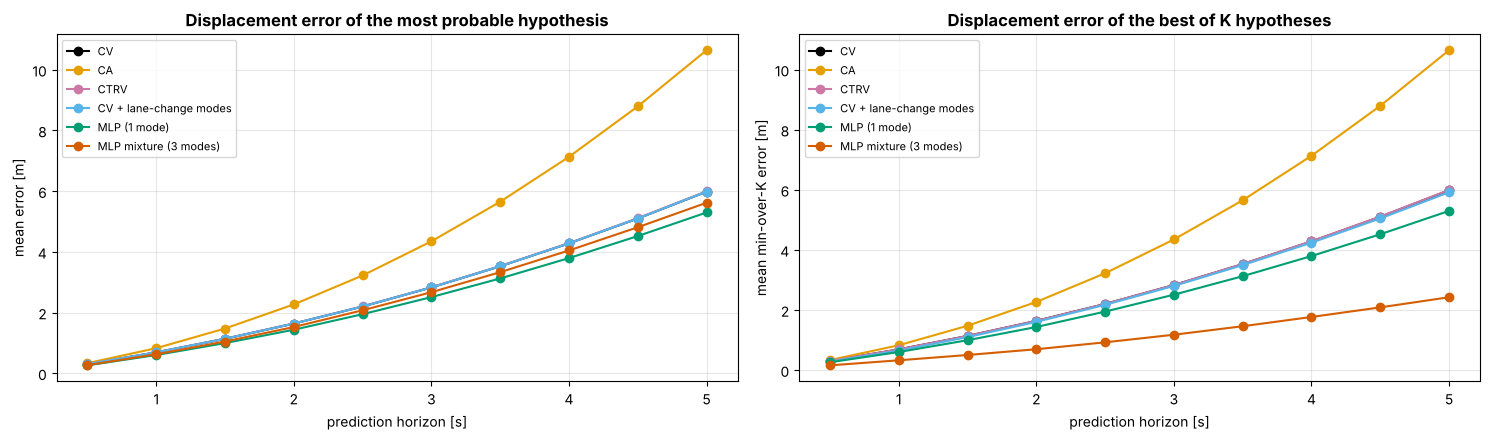

Text summary: lowest FDE: MLP (1 mode) (5.30 m, CV 5.98 m); lowest minFDE_K: MLP mixture (3 modes) (2.42 m); lowest NLL: MLP mixture (3 modes). The 3-mode network's most probable hypothesis has FDE 5.62 m, no better than the 1-mode network (5.30 m): its gain is in coverage, not in the top answer.


In [9]:
def log_density(y, mu, sig, pi):
    # log of a Gaussian mixture with diagonal covariances; y: N x 2, mu/sig: N x K x 2, pi: N x K
    ll = (-0.5 * ((y[:, None] - mu) / sig)**2 - np.log(sig) - 0.5 * np.log(2 * np.pi)).sum(-1)
    m = ll.max(1, keepdims=True)
    return np.log(np.sum(pi * np.exp(ll - m), 1)) + m[:, 0]


def metrics(mu, sig, pi, mask, miss_m=2.0):
    y, mu, sig, pi = FUT[mask], mu[mask], sig[mask], pi[mask]
    d = np.linalg.norm(mu - y[:, None], axis=-1)                    # N x K x T
    top = pi.argmax(1); n = np.arange(len(y))
    return {"K": mu.shape[1], "ADE [m]": d[n, top].mean(), "FDE [m]": d[n, top, -1].mean(),
            "minADE_K [m]": d.mean(-1).min(1).mean(), "minFDE_K [m]": d[..., -1].min(1).mean(),
            "miss rate [%]": 100 * np.mean(d[..., -1].min(1) > miss_m),
            "NLL @ 5 s [nats]": -log_density(y[:, -1], mu[:, :, -1], sig[:, :, -1], pi).mean()}


results = pd.DataFrame({m: metrics(*v, te) for m, v in MODELS.items()}).T
results["K"] = results["K"].astype(int)
print(f"Test set: {te.sum():,} samples")
print(results.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
cols = dict(zip(MODELS, [OI["black"], OI["orange"], OI["purple"], OI["skyblue"], OI["green"], OI["vermillion"]]))
for m, (mu, sig, pi) in MODELS.items():
    d = np.linalg.norm(mu[te] - FUT[te][:, None], axis=-1)
    top = pi[te].argmax(1)
    ax[0].plot(TAU, d[np.arange(te.sum()), top].mean(0), "o-", color=cols[m], label=m)
    ax[1].plot(TAU, d.min(1).mean(0), "o-", color=cols[m], label=m)
ax[0].set(title="Displacement error of the most probable hypothesis", xlabel="prediction horizon [s]", ylabel="mean error [m]")
ax[1].set(title="Displacement error of the best of K hypotheses", xlabel="prediction horizon [s]", ylabel="mean min-over-K error [m]")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

best_fde = results["FDE [m]"].idxmin(); best_min = results["minFDE_K [m]"].idxmin(); best_nll = results["NLL @ 5 s [nats]"].idxmin()
print(f"Text summary: lowest FDE: {best_fde} ({results.loc[best_fde, 'FDE [m]']:.2f} m, CV {results.loc['CV', 'FDE [m]']:.2f} m); "
      f"lowest minFDE_K: {best_min} ({results.loc[best_min, 'minFDE_K [m]']:.2f} m); lowest NLL: {best_nll}. "
      f"The 3-mode network's most probable hypothesis has FDE {results.loc['MLP mixture (3 modes)', 'FDE [m]']:.2f} m, "
      f"no better than the 1-mode network ({results.loc['MLP (1 mode)', 'FDE [m]']:.2f} m): its gain is in coverage, not in the top answer.")

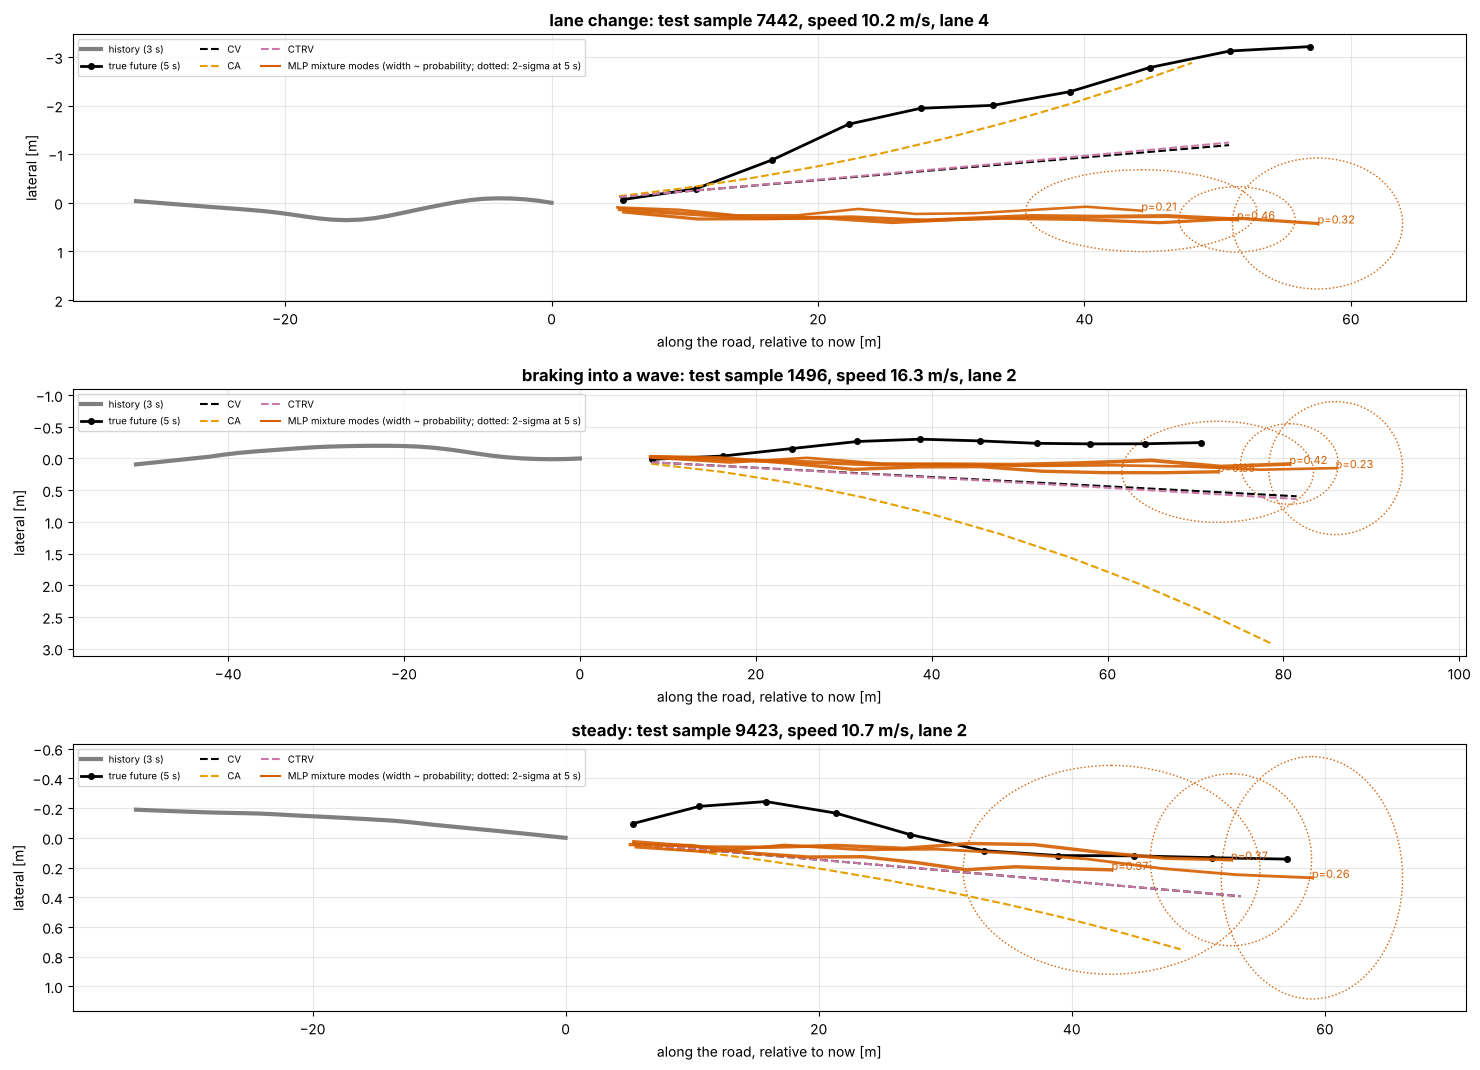

In [10]:
# Three real test cases, each the median-difficulty case for CV within its regime
def pick(regime):
    idx = np.flatnonzero(te & (S["regime"] == regime).values)
    if regime == "lane change":                                  # a complete lane change within the horizon
        idx = idx[np.abs(FUT[idx, -1, 1]) > 0.75 * LANE_W]
    fde_cv = np.linalg.norm(CV[idx, -1] - FUT[idx, -1], axis=-1)
    return idx[np.argsort(fde_cv)[len(idx) // 2]]


from matplotlib.patches import Ellipse
cases = [("lane change", pick("lane change")), ("braking into a wave", pick("braking into a wave")),
         ("steady", pick("steady"))]
fig, axes = plt.subplots(len(cases), 1, figsize=(15, 3.6 * len(cases)))
for ax, (name, i) in zip(axes, cases):
    ax.plot(HIST[i, :, 0], HIST[i, :, 1], color="grey", lw=3, label="history (3 s)")
    ax.plot(FUT[i, :, 0], FUT[i, :, 1], "k.-", lw=2, ms=8, label="true future (5 s)")
    for m in ["CV", "CA", "CTRV"]:
        ax.plot(MODELS[m][0][i, 0, :, 0], MODELS[m][0][i, 0, :, 1], "--", color=cols[m], label=m)
    mu, sig, pi = MODELS["MLP mixture (3 modes)"]
    for k in range(mu.shape[1]):
        ax.plot(mu[i, k, :, 0], mu[i, k, :, 1], "-", color=OI["vermillion"], lw=1 + 4 * pi[i, k], alpha=0.9)
        ax.add_patch(Ellipse(mu[i, k, -1], 4 * sig[i, k, -1, 0], 4 * sig[i, k, -1, 1],
                                                    fill=False, color=OI["vermillion"], ls=":", lw=1))
        ax.annotate(f"p={pi[i, k]:.2f}", mu[i, k, -1], fontsize=8, color=OI["vermillion"])
    ax.plot([], [], color=OI["vermillion"], label="MLP mixture modes (width ~ probability; dotted: 2-sigma at 5 s)")
    ax.set(title=f"{name}: test sample {i}, speed {S.loc[i, 'v_now']:.1f} m/s, lane {S.loc[i, 'lane']}",
           xlabel="along the road, relative to now [m]", ylabel="lateral [m]")
    ax.invert_yaxis(); ax.legend(fontsize=7, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

## 7. Is the predicted uncertainty calibrated?

A predictive distribution is **calibrated** if its $p$-probability region contains the truth in a fraction $p$ of cases. For the Gaussian models the region is an ellipse, and the truth is inside when its squared Mahalanobis distance is below $\chi^2_2(p)$. For mixtures we use the **highest-density region**: the truth is inside the $p$-region when the predicted probability mass of points *more likely than the truth* is at most $p$, which we estimate with 400 samples per prediction. We evaluate at the 5 s horizon.

In [11]:
LEVELS = np.array([0.5, 0.68, 0.8, 0.9, 0.95, 0.99])


def mass_above_truth(mu, sig, pi, mask, h=-1, n_mc=400, seed=SEED):
    # probability mass of the predictive distribution that is denser than the truth (0 = truth at the mode)
    g = np.random.default_rng(seed)
    y, mu, sig, pi = FUT[mask][:, h], mu[mask][:, :, h], sig[mask][:, :, h], pi[mask]
    if pi.shape[1] == 1:
        return chi2.cdf((((y - mu[:, 0]) / sig[:, 0])**2).sum(1), 2)
    N, K = pi.shape
    comp = (g.random((N, n_mc, 1)) > np.cumsum(pi, 1)[:, None, :]).sum(-1).clip(max=K - 1)
    rows = np.arange(N)[:, None]
    samp = mu[rows, comp] + sig[rows, comp] * g.standard_normal((N, n_mc, 2))
    ld_s = np.stack([log_density(samp[:, j], mu, sig, pi) for j in range(n_mc)], 1)
    return np.mean(ld_s >= log_density(y, mu, sig, pi)[:, None], 1)


MASS = {m: mass_above_truth(*v, te) for m, v in MODELS.items()}
cov_tab = pd.DataFrame({m: [np.mean(MASS[m] <= l) for l in LEVELS] for m in MODELS}, index=LEVELS).T
cov_tab.columns = [f"{int(100 * l)} %" for l in LEVELS]
print("Empirical coverage of the nominal prediction regions at 5 s (test set):")
print(cov_tab.round(3).to_string())

Empirical coverage of the nominal prediction regions at 5 s (test set):
                         50 %   68 %   80 %   90 %   95 %   99 %
CV                      0.602  0.739  0.814  0.885  0.924  0.963
CA                      0.627  0.745  0.824  0.882  0.917  0.960
CTRV                    0.612  0.748  0.824  0.887  0.924  0.962
CV + lane-change modes  0.613  0.751  0.831  0.904  0.945  0.985
MLP (1 mode)            0.565  0.743  0.834  0.905  0.937  0.968
MLP mixture (3 modes)   0.492  0.700  0.821  0.913  0.948  0.975


### Repairing coverage with split conformal prediction

Split conformal prediction (Angelopoulos and Bates, 2021; [Notebook 06-05](../06_AI_Safety_ISO_PAS_8800/05_conformal_prediction.ipynb)) turns any score into a region with a finite-sample coverage guarantee. We use the **negative log predictive density** of the true 5 s position as the nonconformity score, compute its conformal quantile $\hat q$ on the **calibration** vehicles, and predict the region $\{\mathbf{y} : -\log p(\mathbf{y}) \le \hat q\}$. If calibration and test samples are exchangeable, it contains the truth with probability at least $1-\alpha$ **on average over samples**. We reuse `avsafety.uq.conformal_threshold`, whose finite-sample quantile rule is the one used throughout the course.

The guarantee is marginal. The table therefore also reports coverage **per regime**, which is what matters when the rare regime is the dangerous one.

Coverage at 5 s, target 90% (test set; calibration on 4,012 samples of separate vehicles):
model                               CV  CV + lane-change modes  MLP (1 mode)  MLP mixture (3 modes)
nominal 90 % region              0.885                   0.904         0.905                  0.913
conformal 90 % region            0.894                   0.897         0.914                  0.918
conformal | steady               0.951                   0.955         0.962                  0.969
conformal | braking into a wave  0.745                   0.741         0.830                  0.818
conformal | accelerating out     0.784                   0.784         0.865                  0.885
conformal | lane change          0.486                   0.486         0.202                  0.165


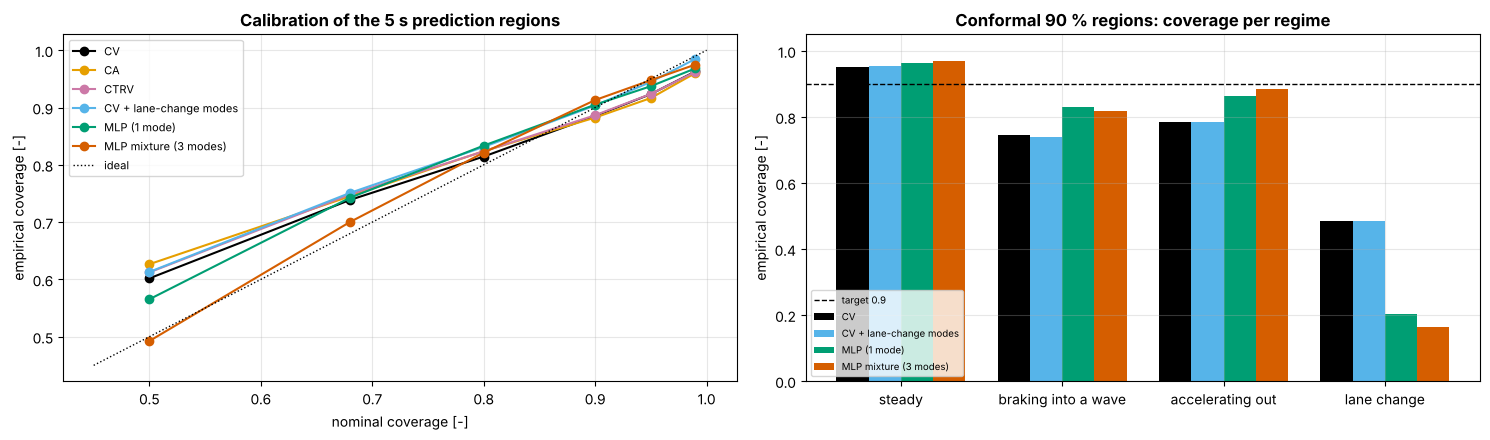

Text summary: every conformal region reaches about 90% overall (0.894-0.918), but in lane changes coverage ranges from 0.17 (MLP mixture (3 modes)) to 0.49 (CV).


In [12]:
ALPHA = 0.10


def nll_score(mu, sig, pi, mask, h=-1):
    return -log_density(FUT[mask][:, h], mu[mask][:, :, h], sig[mask][:, :, h], pi[mask])


REGIMES = ["steady", "braking into a wave", "accelerating out", "lane change"]
rows = []
for m in ["CV", "CV + lane-change modes", "MLP (1 mode)", "MLP mixture (3 modes)"]:
    s_cal = nll_score(*MODELS[m], ca)
    # uq.conformal_threshold scores classes by 1 - p(true class); with a single "class" of
    # probability 1 - s, its score is exactly s and its finite-sample quantile rule applies unchanged
    q = uq.conformal_threshold((1.0 - s_cal)[:, None], np.zeros(len(s_cal), dtype=int), alpha=ALPHA)
    inside = nll_score(*MODELS[m], te) <= q
    nominal = MASS[m] <= 1 - ALPHA
    reg = S.loc[te, "regime"].values
    rows.append({"model": m, "nominal 90 % region": nominal.mean(), "conformal 90 % region": inside.mean(),
                 **{f"conformal | {r}": inside[reg == r].mean() for r in REGIMES}})
conf_tab = pd.DataFrame(rows).set_index("model")
print(f"Coverage at 5 s, target {1 - ALPHA:.0%} (test set; calibration on {ca.sum():,} samples of separate vehicles):")
print(conf_tab.round(3).T.to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for m in MODELS:
    ax[0].plot(LEVELS, cov_tab.loc[m].values, "o-", color=cols[m], label=m)
ax[0].plot([0.45, 1], [0.45, 1], "k:", lw=1, label="ideal")
ax[0].set(title="Calibration of the 5 s prediction regions", xlabel="nominal coverage [-]", ylabel="empirical coverage [-]")
ax[0].legend(fontsize=8)
w = 0.2
for j, m in enumerate(conf_tab.index):
    ax[1].bar(np.arange(len(REGIMES)) + (j - 1.5) * w, [conf_tab.loc[m, f"conformal | {r}"] for r in REGIMES], w,
              color=cols[m], label=m)
ax[1].axhline(1 - ALPHA, color="k", ls="--", lw=1, label="target 0.9")
ax[1].set_xticks(range(len(REGIMES))); ax[1].set_xticklabels(REGIMES)
ax[1].set(title="Conformal 90 % regions: coverage per regime", ylabel="empirical coverage [-]", ylim=(0, 1.05))
ax[1].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
lc_best = conf_tab["conformal | lane change"].idxmax(); lc_worst = conf_tab["conformal | lane change"].idxmin()
print(f"Text summary: every conformal region reaches about {1 - ALPHA:.0%} overall "
      f"({conf_tab['conformal 90 % region'].min():.3f}-{conf_tab['conformal 90 % region'].max():.3f}), but in lane changes "
      f"coverage ranges from {conf_tab.loc[lc_worst, 'conformal | lane change']:.2f} ({lc_worst}) to "
      f"{conf_tab.loc[lc_best, 'conformal | lane change']:.2f} ({lc_best}).")

Two lessons. First, **the nominal regions miss the target in a characteristic way**: the training-spread Gaussians are too wide in the core and too narrow in the far tail, because real prediction errors are heavy-tailed, not Gaussian; the networks, which learn a per-sample spread, track the target more closely in the core but also fall short at the highest levels. Second, **marginal coverage is not conditional coverage**: conformal calibration fixes the average, while the regions remain far too small exactly where vehicles change lanes or brake into a wave, because those cases are rare in the calibration data and the score does not single them out. Group-conditional (Mondrian) conformal prediction, calibrated separately per regime or per detected manoeuvre, is the standard remedy, at the price of needing enough calibration data for each group.

## 8. Failure analysis on real lane changes and stop-and-go waves

In [13]:
reg = S.loc[te, "regime"].values
fde_top, fde_min = {}, {}
for m, (mu, sig, pi) in MODELS.items():
    d = np.linalg.norm(mu[te, :, -1] - FUT[te][:, None, -1], axis=-1)
    fde_top[m] = pd.Series(d[np.arange(len(d)), pi[te].argmax(1)]).groupby(reg).mean()
    fde_min[m] = pd.Series(d.min(1)).groupby(reg).mean()
fde_top, fde_min = pd.DataFrame(fde_top).T[REGIMES], pd.DataFrame(fde_min).T[REGIMES]
print("FDE of the most probable hypothesis [m], by regime (test set):")
print(fde_top.round(2).to_string())
print("\nminFDE_K [m], by regime:")
print(fde_min.round(2).to_string())
print(f"\nText summary: for CV, FDE is {fde_top.loc['CV', 'braking into a wave'] / fde_top.loc['CV', 'steady']:.1f} times "
      f"larger when braking into a wave and {fde_top.loc['CV', 'lane change'] / fde_top.loc['CV', 'steady']:.1f} times "
      f"larger in lane changes than in steady traffic.")

FDE of the most probable hypothesis [m], by regime (test set):
                        steady  braking into a wave  accelerating out  lane change
CV                        4.10                11.98             11.55         7.65
CA                        9.56                13.61             14.16        12.70
CTRV                      4.10                11.98             11.62         7.69
CV + lane-change modes    4.10                11.98             11.55         7.65
MLP (1 mode)              4.11                 8.73              8.87         7.80
MLP mixture (3 modes)     4.34                10.38              8.14         7.90

minFDE_K [m], by regime:
                        steady  braking into a wave  accelerating out  lane change
CV                        4.10                11.98             11.55         7.65
CA                        9.56                13.61             14.16        12.70
CTRV                      4.10                11.98             11.62         7.6

### Does the predictor see the lane change coming?

For the planner, a lane change matters as a possible **cut-in**: it must be predicted before the vehicle crosses into the neighbouring lane. For each test sample whose vehicle changes lane within 5 s, we ask whether the model assigns at least 50 % probability to ending the 5 s horizon beyond the lane boundary (estimated as the midpoint between the median lateral positions of neighbouring lanes), as a function of the time remaining until the lane ID changes. For lane-keeping samples, the same rule gives the **false-alarm** rate.

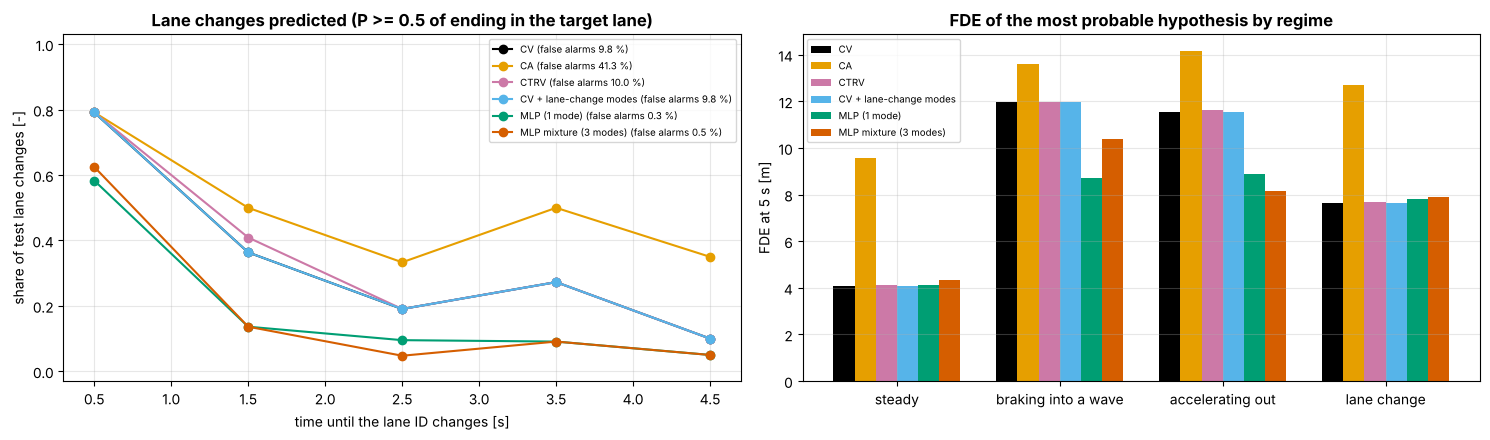

Test lane changes per time-to-change bin: {'(0, 1]': np.int64(24), '(1, 2]': np.int64(22), '(2, 3]': np.int64(21), '(3, 4]': np.int64(22), '(4, 5]': np.int64(20)}
Text summary: with less than 1 s to go, CV predicts 79 % of lane changes but raises false alarms on 9.8 % of lane-keeping samples; the 3-mode network predicts 62 % with 0.5 % false alarms. Three to five seconds ahead, CV recognises 19 % and the network 7 %.


In [14]:
centre = S[tr].groupby("lane")["y0"].median()


def boundary(lane, d):
    return np.array([(centre[l] + centre.get(l + k, centre[l] + k * LANE_W)) / 2 for l, k in zip(lane, d)])


lc = te & S["t_lc"].notna().values
keep = te & S["t_lc"].isna().values
d_lc = S["lc_dir"].values[lc]; b_lc = boundary(S["lane"].values[lc], d_lc); y0_lc = S["y0"].values[lc]
b_left = boundary(S["lane"].values[keep], -np.ones(keep.sum(), int))
b_right = boundary(S["lane"].values[keep], np.ones(keep.sum(), int))
t_bins = pd.cut(S["t_lc"].values[lc], [0, 1, 2, 3, 4, 5])
anticip = {}
for m, (mu, sig, pi) in MODELS.items():
    y_end = y0_lc[:, None] + mu[lc][:, :, -1, 1]
    p_cross = np.sum(pi[lc] * ((y_end - b_lc[:, None]) * d_lc[:, None] > 0), 1)
    y_keep = S["y0"].values[keep][:, None] + mu[keep][:, :, -1, 1]
    p_fa = np.sum(pi[keep] * ((y_keep < b_left[:, None]) | (y_keep > b_right[:, None])), 1)
    anticip[m] = dict(recognised=pd.Series(p_cross >= 0.5).groupby(t_bins, observed=True).mean(),
                      false_alarm=np.mean(p_fa >= 0.5))
n_per_bin = pd.Series(t_bins).value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
centres_t = np.arange(0.5, 5, 1.0)
for m, a in anticip.items():
    ax[0].plot(centres_t, a["recognised"].values, "o-", color=cols[m], label=f"{m} (false alarms {100 * a['false_alarm']:.1f} %)")
ax[0].set(title="Lane changes predicted (P >= 0.5 of ending in the target lane)",
          xlabel="time until the lane ID changes [s]", ylabel="share of test lane changes [-]", ylim=(-0.03, 1.03))
ax[0].legend(fontsize=7)
x = np.arange(len(REGIMES)); w = 0.13
for j, m in enumerate(MODELS):
    ax[1].bar(x + (j - 2.5) * w, fde_top.loc[m].values, w, color=cols[m], label=m)
ax[1].set_xticks(x); ax[1].set_xticklabels(REGIMES)
ax[1].set(title="FDE of the most probable hypothesis by regime", ylabel="FDE at 5 s [m]"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Test lane changes per time-to-change bin:", dict(zip([str(i) for i in n_per_bin.index], n_per_bin.values)))
a_cv, a_mlp = anticip["CV"], anticip["MLP mixture (3 modes)"]
print(f"Text summary: with less than 1 s to go, CV predicts {100 * a_cv['recognised'].iloc[0]:.0f} % of lane changes but raises "
      f"false alarms on {100 * a_cv['false_alarm']:.1f} % of lane-keeping samples; the 3-mode network predicts "
      f"{100 * a_mlp['recognised'].iloc[0]:.0f} % with {100 * a_mlp['false_alarm']:.1f} % false alarms. Three to five seconds "
      f"ahead, CV recognises {100 * a_cv['recognised'].iloc[3:].mean():.0f} % and the network {100 * a_mlp['recognised'].iloc[3:].mean():.0f} %.")

**What the failure analysis shows.**

- **Stop-and-go waves** are the largest longitudinal error source. A vehicle braking into a wave looks, in its own 3 s history, like a cruising vehicle; the cause (the queue ahead) is not in the input. The learned models reduce the error relative to CV, because speed and deceleration history carry some information about the traffic state, but the error remains several times larger than in steady traffic.
- **Constant acceleration** extrapolates a momentary deceleration for 5 s and is worse than CV almost everywhere; a model that is physically "richer" is not automatically better.
- **Lane changes** expose a classic trade-off. CV extrapolates the lateral drift, so it recognises lane changes that are already under way, but it also turns lateral noise into false alarms. The networks have learned that lane changes are rare (about 3 % of training samples) and therefore assign them low probability: few false alarms, but most lane changes are not predicted until the vehicle is almost across. The fixed-prior manoeuvre mixture behaves like CV here: its lane-change hypotheses keep their 1–2 % prior whatever the vehicle does, so they add coverage but no recognition. Rare, safety-relevant manoeuvres need targeted data, balanced training or explicit manoeuvre recognition, and they must be evaluated separately, because the overall metrics barely change when they are wrong.
- **minFDE$_K$ flatters** the 3-mode network: its best hypothesis is close in most cases, but the probability it gives that hypothesis is often low (see the examples above).

## 9. What prediction errors mean for planning

Prediction error is only safety-relevant through the decisions it changes. Two examples connect this notebook to the planning and criticality notebooks.

**Longitudinal: the gap that is not there.** A following vehicle that plans with a prediction of its leader's position needs the leader to be *at least* as far ahead as predicted. When the leader brakes into a wave, an over-estimate of its future position is a **hidden gap deficit**. We compare its distribution at a 3 s horizon with the RSS minimum safe longitudinal distance (Shalev-Shwartz et al., 2017) computed with `avsafety.sotif` (see [Notebook 04-05](../04_SOTIF_ISO21448/05_criticality_metrics_and_rss.ipynb)) using its default parameters (response time 0.5 s, follower acceleration 2 m/s² during the response, braking 4 m/s², leader braking 8 m/s²), for both vehicles at the median current speed of these samples.

Braking-into-a-wave test samples: 517, median speed 12.3 m/s; RSS minimum safe distance at this speed: 19.1 m
Over-estimate of the leader's position at 3 s (positive = leader predicted further ahead than it will be):
                       median [m]  95th percentile [m]  99th percentile [m]  99th pct. / RSS distance [-]
CV                           4.39                10.15                14.91                          0.78
CTRV                         4.39                10.15                14.91                          0.78
MLP (1 mode)                 2.80                 9.03                12.78                          0.67
MLP mixture (3 modes)        3.66                10.29                14.46                          0.76


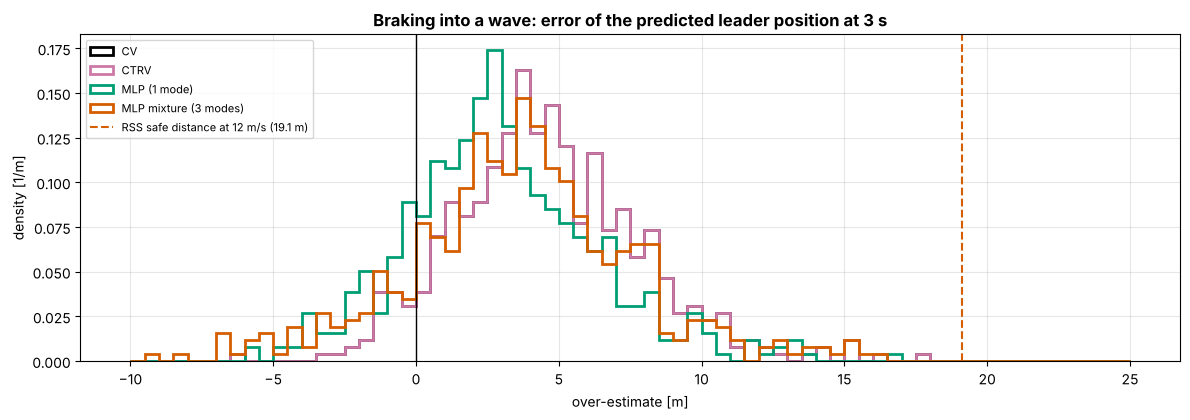

Text summary: even for the best model (MLP (1 mode)) the 99th-percentile over-estimate at 3 s is 12.8 m, 67 % of the RSS safe distance. A planner that trusts the point prediction loses most of its margin in these cases.


In [15]:
H3 = int(np.flatnonzero(np.isclose(TAU, 3.0))[0])
brake = te & (S["regime"] == "braking into a wave").values
v_med = float(np.median(S.loc[brake, "v_now"]))
d_rss = sotif.rss_safe_longitudinal_distance(v_med, v_med)
over = {}
for m in ["CV", "CTRV", "MLP (1 mode)", "MLP mixture (3 modes)"]:
    mu, sig, pi = MODELS[m]
    top = pi[brake].argmax(1)
    over[m] = mu[brake][np.arange(brake.sum()), top, H3, 0] - FUT[brake][:, H3, 0]
gap_tab = pd.DataFrame({m: {"median [m]": np.median(e), "95th percentile [m]": np.percentile(e, 95),
                            "99th percentile [m]": np.percentile(e, 99),
                            "99th pct. / RSS distance [-]": np.percentile(e, 99) / d_rss} for m, e in over.items()}).T
print(f"Braking-into-a-wave test samples: {brake.sum()}, median speed {v_med:.1f} m/s; "
      f"RSS minimum safe distance at this speed: {d_rss:.1f} m")
print("Over-estimate of the leader's position at 3 s (positive = leader predicted further ahead than it will be):")
print(gap_tab.round(2).to_string())

fig, ax = plt.subplots(figsize=(12, 4.3))
bins = np.linspace(-10, 25, 71)
for m, e in over.items():
    ax.hist(e, bins=bins, histtype="step", lw=2, color=cols[m], label=m, density=True)
ax.axvline(0, color="k", lw=1)
ax.axvline(d_rss, color=OI["vermillion"], ls="--", label=f"RSS safe distance at {v_med:.0f} m/s ({d_rss:.1f} m)")
ax.set(title="Braking into a wave: error of the predicted leader position at 3 s", xlabel="over-estimate [m]",
       ylabel="density [1/m]"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
best = gap_tab["99th percentile [m]"].idxmin()
print(f"Text summary: even for the best model ({best}) the 99th-percentile over-estimate at 3 s is "
      f"{gap_tab.loc[best, '99th percentile [m]']:.1f} m, {100 * gap_tab.loc[best, '99th pct. / RSS distance [-]']:.0f} % "
      f"of the RSS safe distance. A planner that trusts the point prediction loses most of its margin in these cases.")

**Lateral: cut-in recognition.** Section 8 measured how long before the lane boundary a lane change is predicted. Every 0.1 s of late recognition is a 0.1 s shorter reaction time for the ego vehicle in a cut-in; with an RSS-style response time of 0.5 s, a cut-in predicted less than a second before the crossing leaves little room to respond comfortably.

**Engineering consequences.**

- A planner should not consume only the most probable trajectory. It should check its plan against **all hypotheses above a probability threshold** and against a **calibrated region** (for example a conformal region per horizon), as proposed for safe planning with conformal prediction by Lindemann et al. (2023). [Notebook 07-02](../07_Runtime_Assurance_and_Operations/02_safe_motion_planning_and_fallback.ipynb) develops this together with fallback behaviour.
- **Formal envelopes** such as RSS do not depend on a learned prediction: they assume the worst case within stated bounds (e.g. maximum braking of the leader). Prediction then makes driving *efficient*, while the envelope keeps it *safe* when prediction is wrong. This division of labour is the reason prediction errors need not be safety-critical, provided the envelope's assumptions hold.
- **Validation targets** must be stated per regime (stop-and-go, lane change, merge), with conditional coverage and recognition latency, because aggregate ADE/FDE hide exactly these cases.

## 10. Beyond this notebook

- **Interaction and context.** Our models see one vehicle's own history. The vehicle ahead (and its braking), neighbouring gaps and the road layout explain most stop-and-go and lane-change behaviour. Social pooling over neighbours was demonstrated on NGSIM by Deo and Trivedi (2018); graph- and transformer-based predictors such as Trajectron++ (Salzmann et al., 2020) and the Motion Transformer, MTR (Shi et al., 2022), condition on all agents and on the map.
- **Benchmarks.** Argoverse (Chang et al., 2019) and the Waymo Open Motion Dataset (Ettinger et al., 2021) provide urban scenes with maps and standard metrics (minADE$_6$, minFDE$_6$, MR, mAP). NGSIM remains useful for highway behaviour, but its known errors (Section 2.2) and single sites mean that results do not transfer automatically.
- **Survey.** Lefèvre, Vasquez and Laugier (2014) remains a clear introduction to the physics-, manoeuvre- and interaction-aware taxonomy and to the link between prediction and risk assessment.

## In industry

Prediction is an ML-heavy component whose errors are handed directly to planning, so its evidence is reviewed under ISO 21448 (performance insufficiencies) and ISO/PAS 8800 (AI component requirements, data and verification).

| Work product | Typical owner | What this notebook contributes |
|---|---|---|
| **Prediction component requirements** (output: hypotheses with probabilities and uncertainty per horizon) | Prediction / behaviour team lead, with the planning architect | Metric set (ADE/FDE, minFDE$_K$, MR, NLL), horizon, and requirements on calibration and recognition latency |
| **SOTIF triggering-condition and performance-limitation analysis** | SOTIF engineer | Stop-and-go waves and lane changes as conditions with measured error inflation; coverage gaps per regime |
| **Data specification and data-quality report** (ISO/PAS 8800) | ML data engineer | Units, re-used IDs, noise and smoothing, leakage-free features, split by vehicle, regime balance |
| **V&V report for the prediction component** | Validation engineer | Per-regime metrics and conditional coverage on held-out data, with sample counts and confidence |
| **Planner–prediction interface and safety concept** | Safety architect | How hypotheses and regions are used, and which formal envelope (e.g. RSS) covers prediction errors |

**What reviewers look for**

- No information leakage: causal feature computation, splits by vehicle/scene and preferably by time or location, and a test set that was never used for tuning.
- Metrics **per regime and class**, with sample counts; rare manoeuvres (cut-ins, merges, hard braking) reported separately, not only inside an average.
- Evidence that predicted uncertainty is **calibrated**, marginally and conditionally, and how the planner uses it.
- A clear statement of which hazards the planner's safety envelope covers *independently* of prediction quality, and which assumptions about other road users it relies on.
- Data provenance and known dataset errors (for NGSIM: video-extraction noise and inconsistencies) documented, with the mitigation used.

## Key takeaways

- Real trajectory data need care before modelling: convert units (feet, ft/s, milliseconds), split re-used vehicle IDs, enforce the time base, and smooth noisy positions, **causally** for inputs and centred only for the reference.
- On congested highway data, constant velocity is a strong baseline; constant acceleration is much worse at 5 s, and CTRV adds nothing on a straight road. A small learned model improves the most probable prediction modestly; a mixture mainly improves **coverage** (minFDE$_K$, NLL).
- **minADE$_K$/minFDE$_K$ ignore probabilities**; likelihood and calibration are needed to judge whether the hypotheses are usable.
- Nominal uncertainty regions are mis-calibrated; split conformal prediction restores **marginal** coverage, but coverage in lane changes and stop-and-go braking stays far below target.
- The hardest real cases are **braking into a wave** (largest longitudinal errors) and **lane changes** (recognised late, or with many false alarms). In planning terms, the tail of the longitudinal error at 3 s is a large fraction of the RSS safe distance, so a planner must use hypotheses and calibrated regions, and rely on a formal envelope for safety.

## Self-assessment

1. Why does smoothing the whole trajectory before cutting history windows inflate a predictor's measured performance?
2. NGSIM US-101 `vehicle_id` 1964 appears at 7:55 and at 8:12. What must the pre-processing do, and why?
3. Why can adding hypotheses never worsen minFDE$_K$, and which metric exposes a predictor that adds them indiscriminately?
4. A predictor's conformal 90 % region has 90.5 % coverage on the test set but 20 % in lane changes. Is the guarantee violated? What would you change?
5. Why is constant acceleration worse than constant velocity at a 5 s horizon in stop-and-go traffic?
6. How does a formal safety envelope such as RSS change the safety relevance of prediction errors, and what does it rely on instead?

<details><summary>Answers</summary>

1. The smoothed value at the last history step then depends on future positions, so the input contains information that is not available online. All models look better than they will be in the vehicle.
2. IDs are unique only within a 15-minute period, so the two appearances are different vehicles. Segments must be split at time gaps, otherwise a trajectory would "jump" 17 minutes and corrupt velocities and samples.
3. minFDE$_K$ takes the best of the hypotheses with hindsight; an extra hypothesis can only reduce the minimum. NLL (and calibration) expose indiscriminate hypotheses, because probability mass spread over unlikely futures lowers the density at the true future.
4. No: split conformal prediction guarantees **marginal** coverage under exchangeability, not coverage within a subgroup. Use group-conditional (Mondrian) calibration per regime or recognised manoeuvre, collect more lane-change data, or improve the score so that it reflects manoeuvre uncertainty.
5. A momentary deceleration (or acceleration) estimated from a short, noisy history is extrapolated quadratically over 5 s, whereas real accelerations in stop-and-go traffic change sign within a few seconds.
6. The envelope bounds the other road users' behaviour (e.g. maximum braking of the leader) and keeps a distance that is safe for every behaviour within those bounds, so a wrong prediction reduces comfort and efficiency rather than safety. It relies on the bounds being correct for the ODD (and on correct perception of the current state), which must itself be justified.
</details>

## References

- Alexiadis, V., Colyar, J., Halkias, J., Hranac, R., McHale, G. (2004). The Next Generation Simulation program. *ITE Journal*, 74(8), 22–26.
- Angelopoulos, A. N., Bates, S. (2021). A gentle introduction to conformal prediction and distribution-free uncertainty quantification. arXiv:2107.07511. https://arxiv.org/abs/2107.07511
- Bishop, C. M. (1994). *Mixture density networks*. Technical Report NCRG/94/004, Aston University.
- Chai, Y., Sapp, B., Bansal, M., Anguelov, D. (2019). MultiPath: multiple probabilistic anchor trajectory hypotheses for behavior prediction. *Conference on Robot Learning (CoRL 2019)*, PMLR 100, 86–99. https://arxiv.org/abs/1910.05449
- Chang, M.-F., et al. (2019). Argoverse: 3D tracking and forecasting with rich maps. *IEEE/CVF CVPR 2019*, 8740–8749. https://doi.org/10.1109/CVPR.2019.00895
- Coifman, B., Li, L. (2017). A critical evaluation of the Next Generation Simulation (NGSIM) vehicle trajectory dataset. *Transportation Research Part B*, 105, 362–377. https://doi.org/10.1016/j.trb.2017.09.018
- Deo, N., Trivedi, M. M. (2018). Convolutional social pooling for vehicle trajectory prediction. *IEEE/CVF CVPR Workshops 2018*. https://doi.org/10.1109/CVPRW.2018.00196
- Ettinger, S., et al. (2021). Large scale interactive motion forecasting for autonomous driving: the Waymo Open Motion Dataset. *IEEE/CVF ICCV 2021*, 9690–9699. https://doi.org/10.1109/ICCV48922.2021.00957
- Federal Highway Administration (2007). *US Highway 101 Dataset* (NGSIM fact sheet FHWA-HRT-07-030). https://www.fhwa.dot.gov/publications/research/operations/07030/
- ISO 21448:2022. *Road vehicles — Safety of the intended functionality*. International Organization for Standardization.
- ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence*. International Organization for Standardization.
- Lefèvre, S., Vasquez, D., Laugier, C. (2014). A survey on motion prediction and risk assessment for intelligent vehicles. *ROBOMECH Journal*, 1, 1. https://doi.org/10.1186/s40648-014-0001-z
- Lindemann, L., Cleaveland, M., Shim, G., Pappas, G. J. (2023). Safe planning in dynamic environments using conformal prediction. *IEEE Robotics and Automation Letters*, 8(8), 5116–5123. https://doi.org/10.1109/LRA.2023.3292071
- Punzo, V., Borzacchiello, M. T., Ciuffo, B. (2011). On the assessment of vehicle trajectory data accuracy and application to the Next Generation SIMulation (NGSIM) program data. *Transportation Research Part C*, 19(6), 1243–1262. https://doi.org/10.1016/j.trc.2010.12.007
- Salzmann, T., Ivanovic, B., Chakravarty, P., Pavone, M. (2020). Trajectron++: dynamically-feasible trajectory forecasting with heterogeneous data. *Computer Vision – ECCV 2020*, LNCS, 683–700. https://doi.org/10.1007/978-3-030-58523-5_40
- Schubert, R., Richter, E., Wanielik, G. (2008). Comparison and evaluation of advanced motion models for vehicle tracking. *11th International Conference on Information Fusion (FUSION 2008)*, 1–6.
- Shalev-Shwartz, S., Shammah, S., Shashua, A. (2017). On a formal model of safe and scalable self-driving cars. arXiv:1708.06374. https://arxiv.org/abs/1708.06374
- Shi, S., Jiang, L., Dai, D., Schiele, B. (2022). Motion Transformer with global intention localization and local movement refinement. *Advances in Neural Information Processing Systems 35 (NeurIPS 2022)*, 6531–6543.
- Thiemann, C., Treiber, M., Kesting, A. (2008). Estimating acceleration and lane-changing dynamics from Next Generation Simulation trajectory data. *Transportation Research Record*, 2088, 90–101. https://doi.org/10.3141/2088-10

---
**Navigation:** ← [08 Driving datasets](08_driving_datasets.ipynb) · [Module index](README.md) · [Module 02: Failures and Robustness](../02_Failures_and_Robustness/README.md) →